In [1]:
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.datasets import california_housing

(inputs, targets), (x_test, y_test) = california_housing.load_data(version='large', 
                                        test_split=0.2)
print(inputs.shape, targets.shape)
print(x_test.shape, y_test.shape)

2026-10-30 20:04:50.528353: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


(16512, 8) (16512,)
(4128, 8) (4128,)


In [2]:
# tarkastellaan jakoa
print(f"treenidatan prosentuaalinen koko: {inputs.shape[0] * 100 / (inputs.shape[0] + x_test.shape[0])}%")

print(f"testidatan prosentuaalinen koko: {x_test.shape[0] * 100 / (inputs.shape[0] + x_test.shape[0])}%")

treenidatan prosentuaalinen koko: 80.0%
testidatan prosentuaalinen koko: 20.0%


## Tarkastelaan mikä on noin 20% validointidataa varte

In [3]:
print(inputs.shape[0]*0.8)

13209.6


In [4]:
# Datan jako treeni ja validointi dataan

x_train = inputs[:13210]  # 80 %
y_train = targets[:13210]

x_val = inputs[13210:]    # 20 %
y_val = targets[13210:]

## Standardoidaan treenidata

In [5]:
# Keskiarvo ja keskihajonta lasketaan vain treenidatasta
mean = x_train.mean(axis=0)
std = x_train.std(axis=0)
x_train -= mean
x_train /= std
x_test -= mean
x_test /= std
x_val -= mean
x_val /= std

# Tarkastellaan 5 ensimmäistä tulosta
print(f"x_train: {x_train[:5]}\n")
print(f"\nx_test: {x_test[:5]}\n")
print(f"\n*x_val:{x_val[:5]}")

x_train: [[ 0.64817595 -0.72325134  1.8523254  -0.1423819   0.03717746 -0.33747348
  -0.02615599 -0.04231323]
 [ 0.6032096  -0.7842549  -0.6160796  -0.38028157  0.03953399 -0.12743522
   0.14472961 -0.6001542 ]
 [-1.4101954   0.9989102   1.8523254  -0.3462959  -0.26445818 -0.6339981
  -0.26694933  0.05670711]
 [ 0.8080492  -0.8030255  -1.4123393   0.22013186  0.39301327  0.144379
   0.4994467   0.25231847]
 [-1.4751426   1.0739908  -0.3772017  -1.006071   -1.119878   -1.1184982
  -1.1032531   5.660519  ]]


x_test: [[ 0.6032096  -0.7279431   1.2949437  -0.20219667 -0.13249259 -0.145968
  -0.11936631 -0.2526588 ]
 [-0.3160606  -0.46985373 -1.1734614   0.0026236  -0.05708368  0.04995004
  -0.03392351  0.3100408 ]
 [-0.8206621   1.0223743  -1.6512172  -0.34357706 -0.5684504  -0.38071665
  -0.51809937  0.7014219 ]
 [-1.245325    1.0411432  -0.9345835   2.1903944   2.3960624   0.5838708
   2.4542744  -0.11677655]
 [ 1.0828294  -0.77956134  0.7375619  -0.57014817 -0.7098421  -0.6895965
  -0.

In [6]:
# Tarkastellaan kohdearvoja (10 ensimmäistä)
print(f"y_train (10 ensimmäistä):\n{y_train[:10]}\n")
print(f"y_test (10 ensimmäistä):\n{y_test[:10]}\n")
print(f"y_val (10 ensimmäistä):\n{y_val[:10]}")

y_train (10 ensimmäistä):
[252300. 146900. 290900. 141300. 500001.  72000. 252400. 162500. 500001.
 226800.]

y_test (10 ensimmäistä):
[397900. 227900. 172100. 186500. 148900.  65600. 344600. 235600. 233000.
 192100.]

y_val (10 ensimmäistä):
[ 77500. 120400. 208000. 143800. 109800.  74000. 315500. 127000. 278800.
 500001.]


In [7]:
# arvot ovat 100 tuhansissa tai lähellä -> jaetaan 100000:lla
y_train /= 1e5
y_test /= 1e5
y_val /= 1e5

# Tarkastellaan kohdearvoja jaon jälkeen (10 ensimmäistä)
print(f"y_train (10 ensimmäistä):\n{y_train[:10]}\n")
print(f"y_test (10 ensimmäistä):\n{y_test[:10]}\n")
print(f"y_val (10 ensimmäistä):\n{y_val[:10]}\n")

y_train (10 ensimmäistä):
[2.523   1.469   2.909   1.413   5.00001 0.72    2.524   1.625   5.00001
 2.268  ]

y_test (10 ensimmäistä):
[3.979 2.279 1.721 1.865 1.489 0.656 3.446 2.356 2.33  1.921]

y_val (10 ensimmäistä):
[0.775   1.204   2.08    1.438   1.098   0.74    3.155   1.27    2.788
 5.00001]



## Baseline mallin rakennus ja koulutus

In [8]:
# Baseline malli, ilman ylisovittamisen tuontia
model_baseline = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

# configure the learning algorithm
model_baseline.compile(optimizer='adam',loss='mse',metrics=['mae'])

I0000 00:00:1793383493.702610     594 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 21861 MB memory:  -> device: 0, name: AMD Radeon RX 7900 XTX, pci bus id: 0000:03:00.0


In [9]:
# Ekan ajon 500 epoch huomasin että 300 epochia riitti jo todistamaan ylisovituksen.
histories = {}

epochs = 300

histories["Baseline malli"] = model_baseline.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

2026-10-30 20:04:55.372068: I external/local_xla/xla/service/service.cc:163] XLA service 0x71c4ec00dcc0 initialized for platform ROCM (this does not guarantee that XLA will be used). Devices:
2026-10-30 20:04:55.372086: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): AMD Radeon RX 7900 XTX, AMDGPU ISA version: gfx1100
2026-10-30 20:04:55.385337: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-30 20:04:55.474415: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 20:04:55.474447: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none o

## Baseline-mallin valinta

Aluksi kokeilin erilaisia neuroverkkoarkkitehtuureja ilman regularisointia. Kokeilin ensin pienempää mallia, jossa oli kaksi piilokerrosta (32 ja 16 neuronia), sekä suurempaa mallia, jossa oli kolme piilokerrosta (64, 64 ja 32 neuronia).

Tämän jälkeen kokeilin vielä kolmea suurempaa mallia, joiden piilokerroksissa oli 128/128/64, 256/256/128 ja 512/256/128/64 neuronia.

Lopulta valitsin 128/128/64-mallin, koska siinä ylisovittuminen näkyi erittäin selvästi. Malli oli myös kevyempi kouluttaa kuin kaksi suurinta mallia.

## L2 reguloimalla ylisovittamisen estäminen

In [10]:
from keras.regularizers import l2

epochs = 300

# L2 0.0001
model_L2_00001 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.0001)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.0001)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.0001)),
    Dense(1)
])

model_L2_00001.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.0001"] = model_L2_00001.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# L2 0.001
model_L2_0001 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(1)
])

model_L2_0001.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001"] = model_L2_0001.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# L2 0.01
model_L2_001 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1)
])

model_L2_001.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.01"] = model_L2_001.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

## Johtopäätökset

Huomasin, että L2-regularisoinnin pienentäminen eli painokertoimien rankaisun vähentäminen lisäsi ylisovittamisen merkkejä. Testasin arvoja 0.0001, 0.001 ja 0.01. Pienimmällä arvolla training loss jatkoi laskuaan, vaikka validation loss tasaantui ja alkoi hieman kasvaa. Suurimmalla arvolla 0.01 regularisointi vaikutti puolestaan liian voimakkaalta, sillä mallin validation MAE jäi muita heikommaksi. Tämä viittaa siihen, että regularisointi rajoitti mallin oppimista liikaa.

Parhaan validation MAE:n saavutti L2 0.0001 (0.3234) 173. epochilla. L2 0.001 saavutti MAE-arvon 0.3368 ja L2 0.01 arvon 0.3653. Valitsisin kuitenkin jatkoon L2-arvon 0.001, koska sen koulutuskäyrissä ylisovittamisen merkit olivat maltillisempia kuin pienimmällä L2-arvolla, eikä regularisointi vaikuttanut yhtä voimakkaalta kuin arvolla 0.01. Vaikka validation MAE jäi hieman heikommaksi kuin arvolla 0.0001, L2 0.001 vaikutti hyvältä kompromissilta mallin oppimiskyvyn ja ylisovittamisen vähentämisen välillä.

## Dropout

Kokeillaan dropourir arvoilla 0.1, 0.2 ja 0.3 ja pidetään taas vain paras/lupaavin tulos.

In [11]:
from keras.layers import Dropout

epochs = 300

# Dropout 10 %
model_D1 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    Dropout(0.1),
    Dense(128, activation='relu'),
    Dropout(0.1),
    Dense(64, activation='relu'),
    Dropout(0.1),
    Dense(1)
])

model_D1.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["Dropout 10%"] = model_D1.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# Dropout 20 %
model_D2 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(1)
])

model_D2.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["Dropout 20%"] = model_D2.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# Dropout 30 %
model_D3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(1)
])

model_D3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["Dropout 30%"] = model_D3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

2026-10-30 20:26:51.101542: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 20:26:51.101576: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 20:26:51.101581: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-30 20:26:54.483608: I external/l

## Dropout-johtopäätökset

Testasin Dropout-regularisointia arvoilla 0.1, 0.2 ja 0.3. Pienimmällä arvolla ylisovittamisen merkkejä esiintyi edelleen, sillä training loss jatkoi laskuaan validation lossin pysyessä lähes muuttumattomana. Suuremmilla Dropout-arvoilla validation loss pysyi tasaisempana koulutuksen loppupuolella, mikä voi viitata ylisovittamisen vähenemiseen.

Parhaan validation MAE:n saavutti Dropout 0.2 (0.3268) 259. epochilla. Dropout 0.1 saavutti MAE-arvon 0.3279 ja Dropout 0.3 arvon 0.3335. Erot olivat melko pieniä, mutta voimakkaampi Dropout 0.3 ei siis parantanut MAE-tulosta.

Valitsisin jatkoon Dropout 0.2 -mallin, koska se saavutti pienimmän validation MAE:n. Dropout 0.3 saattoi vähentää ylisovittamista voimakkaamman regularisoinnin ansiosta, mutta sen MAE oli hieman heikompi. Dropout 0.2 vaikutti siis parhaalta kompromissilta ylisovittamisen vähentämisen ja mallin ennustustarkkuuden välillä.

## BatchNormalization kokeilu

Kokeillaan miten BatchNormalization vaikuttaa. Kokeilen jos lisään vain yhteen, kahteen tai kaikkiin kolmeen kerrokseen. Testasin vain ekan tason normalisointia, ekan ja tokan, sekä kaikkien tasojen normalisointia.

In [12]:
from keras.layers import BatchNormalization

epochs = 300

# BatchNormalization 1 kerros
model_BN1 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

model_BN1.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["BatchNormalization 1 BN"] = model_BN1.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# BatchNormalization 2 kerrosta
model_BN2 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(64, activation='relu'),
    Dense(1)
])

model_BN2.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["BatchNormalization 2 BN"] = model_BN2.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# BatchNormalization 3 kerrosta
model_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dense(1)
])

model_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["BatchNormalization 3 BN"] = model_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

## BatchNormalization-johtopäätökset

Pelkkä BatchNormalization ei siis poistanut ylisovittamisen merkkejä, mutta paransi hieman parasta MAE-tulosta baseline-malliin verrattuna (0.3376). Se ei kuitenkaan saavuttanut L2-regularisoinnin (0.3234) tai Dropoutin (0.3268) parasta validation MAE:tä. Vaikka kahden kerroksen normalisointi saavutti hieman paremman validation MAE:n, valitsisin jatkoon kolmen kerroksen normalisoinnin. Sen kuvaajissa training- ja validation-lossien välinen ero oli pienempi, mikä voi viitata vähäisempään ylisovittamiseen. MAE-arvojen ero oli myös hyvin pieni (0.0007). Seuraavaksi kokeilen eri regularisointimenetelmien yhdistelmiä ja selvitän, parantaako niiden yhdistäminen mallin tuloksia

## Yhdistelmäkokeilut

Selvästi vähiten ylioppimista vähensi BatchNormalisation. Siksi en erikseen testaa sitä yksinään vaan testaan mallit: L2 0.001 + DropOut 10%, L2 0.001 + BatchNormalization 3 BN, DropOut 10% + BatchNormalization 3 BN ja kaikki 3 eli L2 0.001 + DropOut 20% + BatchNormalization 3 BN.

In [20]:
# L2 0.001 + DropOut 20%
epochs = 300

model_L2_D1 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(1)
])

model_L2_D1.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 20%"] = model_L2_D1.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# L2 0.001 + BatchNormalization 3 BN
model_L2_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dense(1)
])

model_L2_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + BatchNormalization 3 BN"] = model_L2_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# DropOut 20% + BatchNormalization 3 BN
model_D1_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1)
])

model_D1_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["DropOut 20% + BatchNormalization 3 BN"] = model_D1_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)


# L2 0.001 + DropOut 20% + BatchNormalization 3 BN
model_L2_D1_BN3 = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1)
])

model_L2_D1_BN3.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 20% + BatchNormalization 3 BN"] = model_L2_D1_BN3.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), verbose=0)

## Yhdistelmäjohtopäätökset

Kaikkien kolmen regularisointimenetelmän yhdistelmän mallilla koulutuskäyrät olivat hyvin tasaisia ja training- sekä validation loss pysyivät lähellä toisiaan. Malli jäi kuitenkin validation MAE -arvolla (0.3454) jälkeen muista lupaavimmista malleista. Tämä voi viitata siihen, että regularisointia oli liikaa ja mallin oppiminen rajoittui.

Parhaan yhdistelmämallin tuloksen saavutti Dropout 20 % + BatchNormalization 3 BN, jonka validation MAE oli 0.3292. Kolmen menetelmän yhdistelmän ero tähän oli 0.0162 eli noin 1620 dollaria keskimääräisessä ennustevirheessä. Pelkkä Dropout 20 % saavutti kuitenkin hieman paremman MAE:n (0.3268), joten BatchNormalizationin lisääminen ei tässä kokeilussa parantanut tulosta.

Vaikka kaikkien kolmen yhdistelmän koulutuskäyrät olivat tasaisimmat, niiden läheisyys ei yksin osoita vähäisempää ylisovittamista tai parempaa ennustustarkkuutta. Valitsisin jatkokokeiluihin Dropout 20 % + BatchNormalization 3 BN -mallin, koska se saavutti yhdistelmämalleista parhaan validation MAE:n.

## EarlyStopping

Kokeillaan seuraavaksi EarlyStoppingia kahdella yhdistelmämallilla: Dropout 20 % + BatchNormalization 3 BN ja L2 0.001 + Dropout 20 % + BatchNormalization 3 BN. Ensimmäinen saavutti parhaan validation MAE:n yhdistelmämalleista ja jälkimmäisellä oli hyvin tasaiset koulutuskäyrät. Näin voidaan tutkia, parantaako EarlyStopping mallien tuloksia ja vähentääkö se ylisovittamista.

Asetetaan patience-arvoksi 40 ja monitoroidaan val_mae:a. Maksimiksi asetetaan 1000 epochia, jotta malleilla on riittävästi aikaa oppia. EarlyStopping pysäyttää koulutuksen, jos validation MAE ei parane 40 peräkkäisen epochin aikana. Restore_best_weights palauttaa mallin painot parhaan validation MAE:n saavuttaneelta epochilta. EarlyStopping ei kuitenkaan takaa ylisovittamisen poistumista, mutta voi vähentää sitä ja turhaa koulutusta.

In [14]:
from keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_mae',
    patience=40,
    mode='min',
    restore_best_weights=True # Palauttaa parhaat painot pysäytyksen jälkeen.
)

In [23]:
epochs = 1000

# L2 0.001 + DropOut 20% + BatchNormalization 3 BN + EarlyStopping
model_L2_D2_BN3_ES = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1)
])

model_L2_D2_BN3_ES.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 20% + BatchNormalization 3 BN + EarlyStopping"] = model_L2_D2_BN3_ES.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), callbacks=[EarlyStopping(monitor='val_mae', patience=40, restore_best_weights=True)], verbose=0)


# L2 0.001 + DropOut 20% + EarlyStopping
model_L2_D2_ES = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(1)
])

model_L2_D2_ES.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["L2 0.001 + DropOut 20% + EarlyStopping"] = model_L2_D2_ES.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), callbacks=[EarlyStopping(monitor='val_mae', patience=40, restore_best_weights=True)], verbose=0)


# DropOut 20% + BatchNormalization 3 BN + EarlyStopping
model_D2_BN3_ES = Sequential([
    Input(shape=(8,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(1)
])

model_D2_BN3_ES.compile(optimizer='adam', loss='mse', metrics=['mae'])

histories["DropOut 20% + BatchNormalization 3 BN + EarlyStopping"] = model_D2_BN3_ES.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_data=(x_val, y_val), callbacks=[EarlyStopping(monitor='val_mae', patience=40, restore_best_weights=True)], verbose=0)

KeyboardInterrupt: 

## Johtopäätökset

Aikaisemmin parhaaksi malliksi valitulla L2 0.001 + DropOut 10% mallilla pysäytettiin koulutus hieman aikaisemmin ja validaatio MAE loss arvo heikkeni 0,0054 (|0,3590 - 0,3536|). Ero on on pieni ja koulutusaika on huomattavasti parempi. Joten early stopping paransi koulutusaikaa heikentämällä val MAE arvoa. EarlyStoppingilla val ja train erot olivat ilman: 0,0001 (|0,3536 - 0,3535|) ja pysäyttimellä: 0,0028 (|0,3590 - 0,3562|). Näiden erotus välinen ero oli vain 0,0027. 

Toiseksi testiin valitulla kolmen regularisointimenetelmän mallilla L2 0.001 + DropOut 10% + BatchNormalization 3 BN EarlyStopping pysäytti koulutuksen aikaisemmin, mutta validaatio MAE -arvo heikkeni 0,0064 (|0,3698 - 0,3634|). Ero oli siis hieman suurempi kuin ensimmäisellä mallilla. EarlyStoppingilla val ja train MAE erot olivat ilman: 0,0292 (|0,3634 - 0,3926|) ja pysäyttimellä: 0,0283 (|0,3698 - 0,3981|). Näiden erotusten välinen ero oli vain 0,0009 (|0,0292 - 0,0283|). EarlyStopping siis pienensi hieman koulutus- ja validaatio-MAE välistä eroa sekä lyhensi koulutusta, mutta heikensi validaatio MAE -arvoa.

EarlyStopping siis tehostaa kouluttamista, mutta muuttaa hieman val MAE arvoa laskien keskimäärin. Val ja train MAE erotukset parani 3 regulointi menetelmän mallissa, mutta val MAE jää matalaksi. Sen voi siis poissulkea. Val ja train MAE erotukset heikkeni L2 0.001 + DropOut 10% mallilla pysäyttimen kanssa ja myös paras val MAE laski hieman. Mutta pysäytin takaa ettei malli yliopi ja se heikensi vain erotusta pienellä. Samalla koulutusaika parani. Eli L2 0.001 + DropOut 10% malli EarlyStoppingilla on siis ylioppimisen mukaan paras malli.

## Kaikkien paitsi eri Baseline mallien koulutuskäyrät

Jätin nämä tänne perustelujen selkeyttämiseksi. Poisitin koulutetut mallit ylläolevista koodeista.

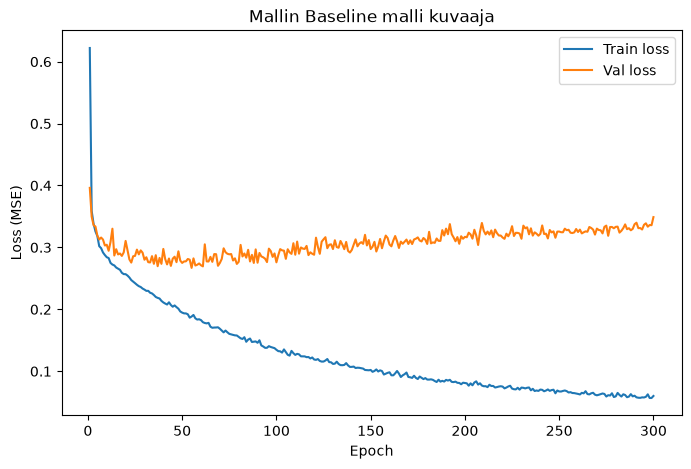

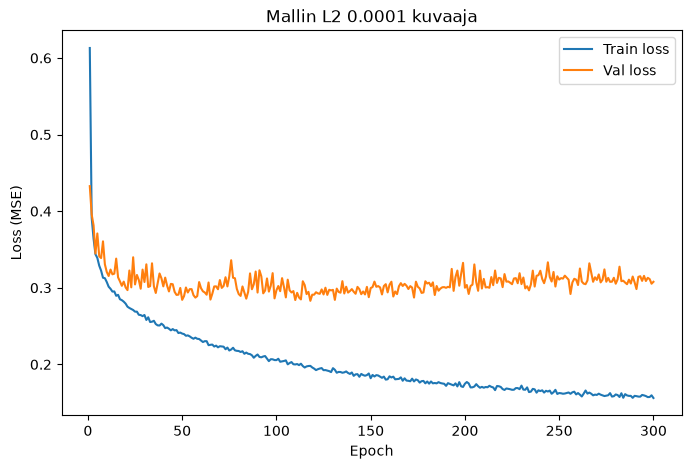

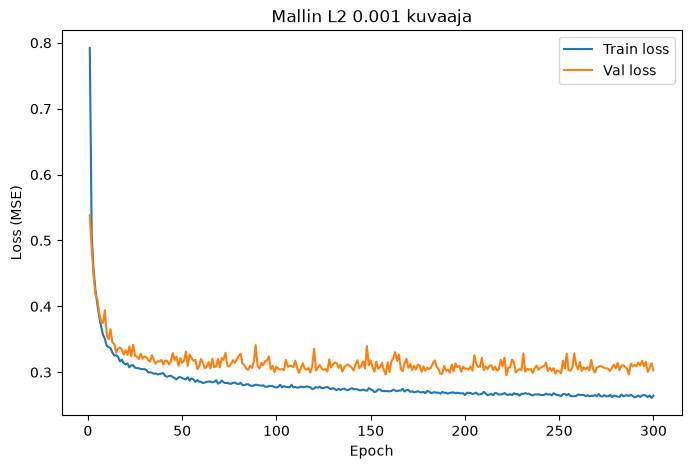

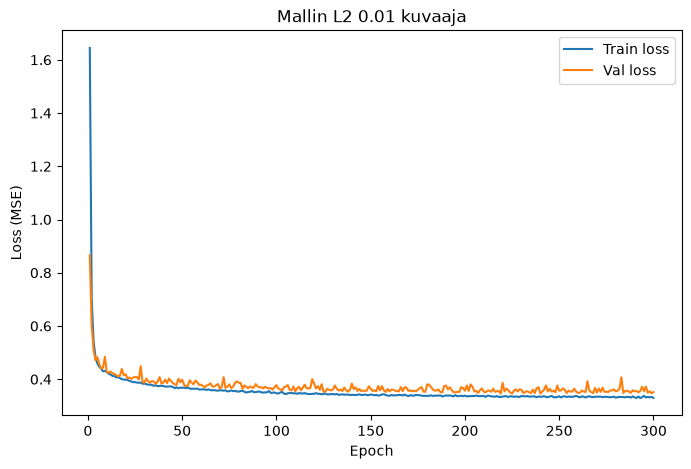

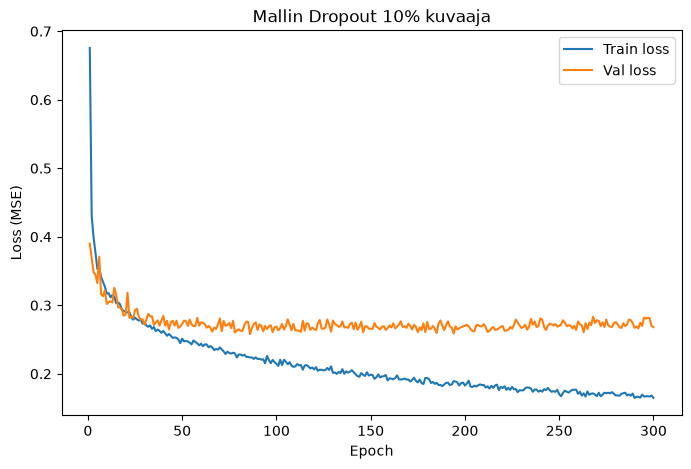

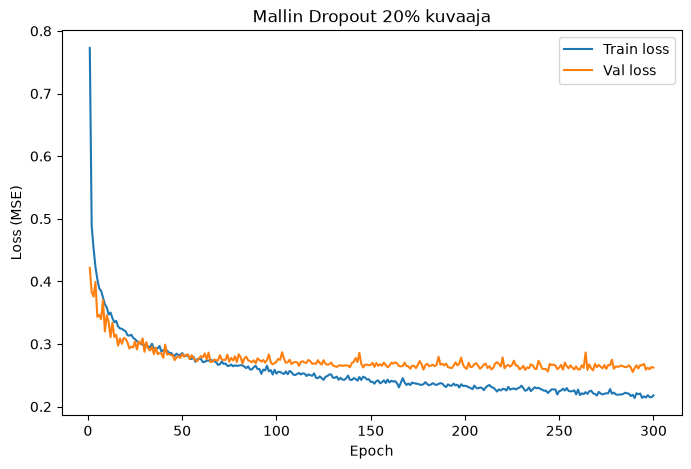

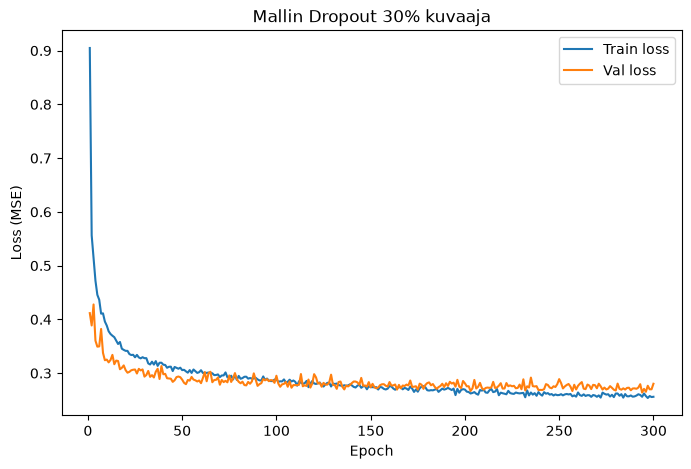

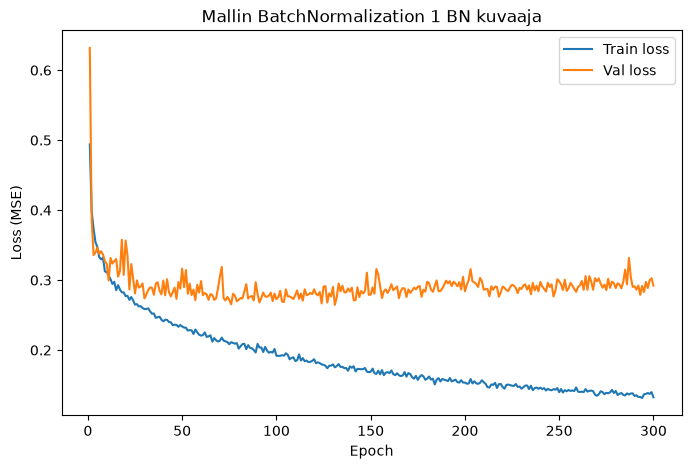

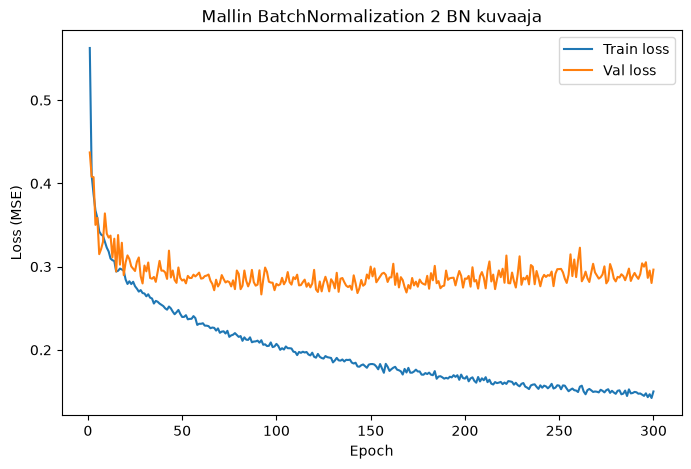

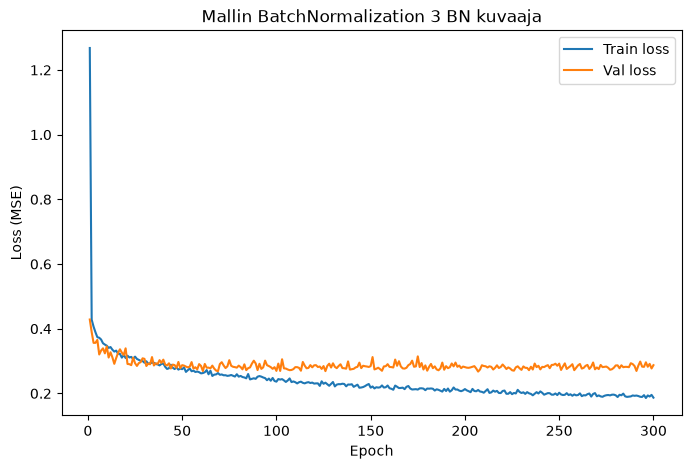

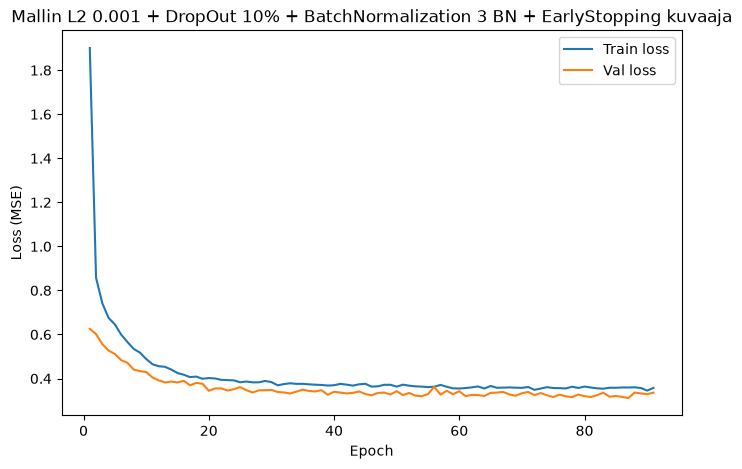

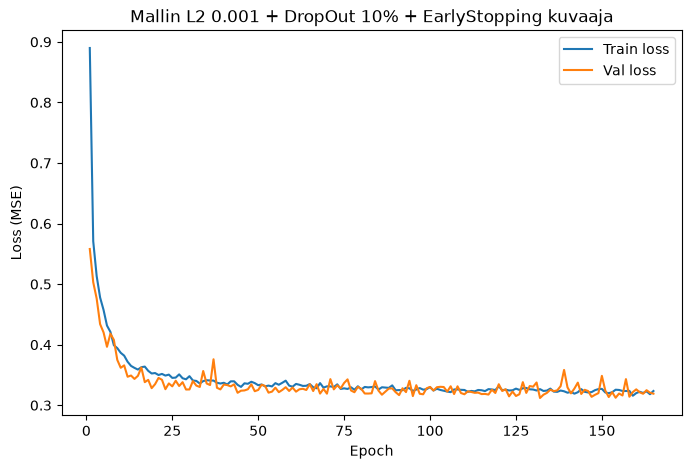

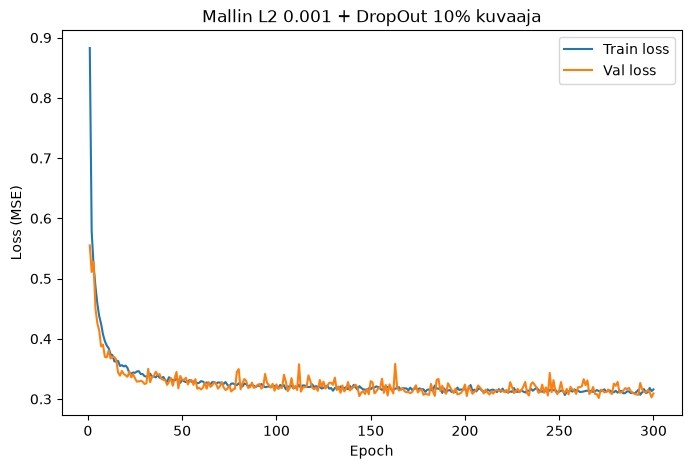

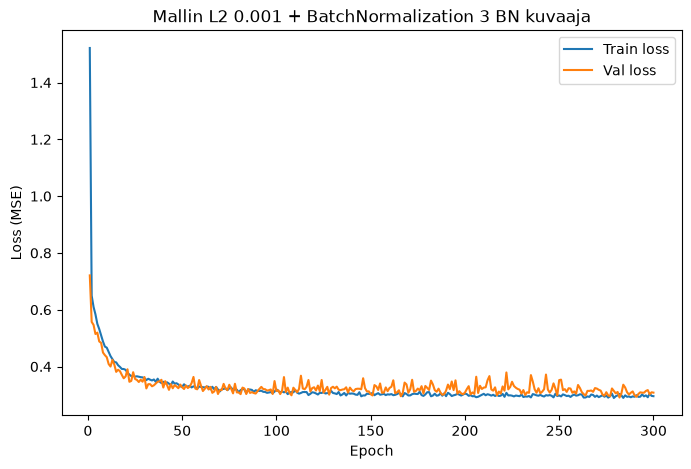

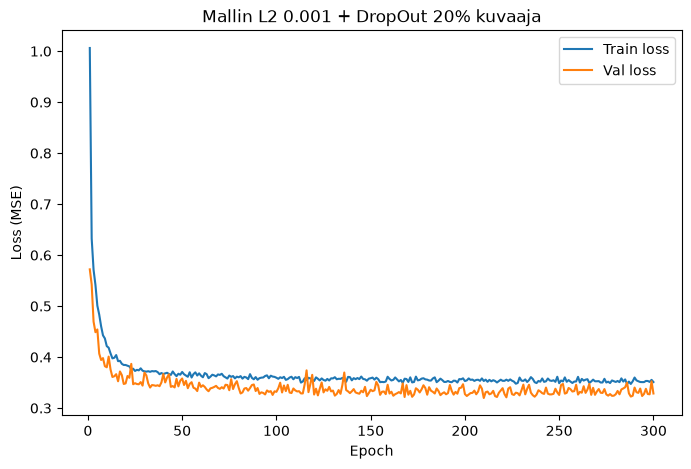

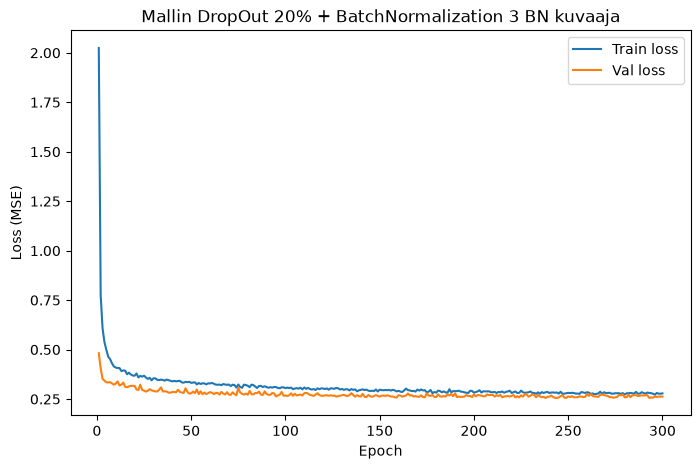

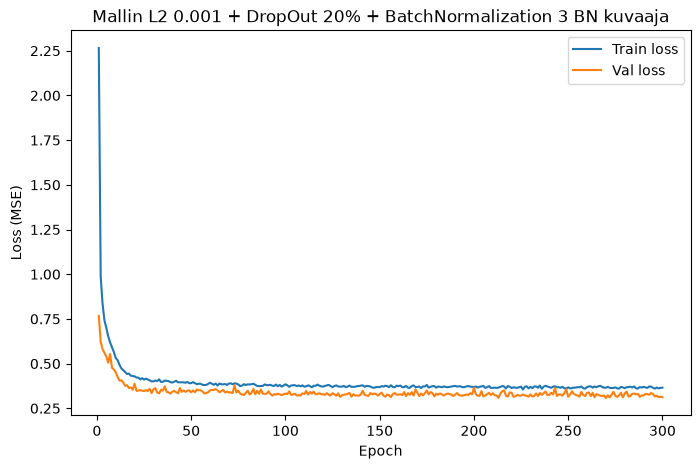

In [21]:
for model, history in histories.items():
    plt.figure(figsize=(8, 5))

    epochs = range(1, len(history.history['loss']) + 1)

    plt.plot(epochs, history.history['loss'], label='Train loss')
    plt.plot(epochs, history.history['val_loss'], label='Val loss')

    plt.legend()
    plt.title(f"Mallin {model} kuvaaja")
    plt.xlabel('Epoch')
    plt.ylabel('Loss (MSE)')
    plt.show()
    print("")

## Viimeiset EarlyStoppin kokeilun koulutuskäyrät

In [ ]:
models = [
    ("L2 0.001 + DropOut 20%", "L2 0.001 + DropOut 20% + EarlyStopping"),
    ("L2 0.001 + DropOut 20% + BatchNormalization 3 BN", "L2 0.001 + DropOut 20% + BatchNormalization 3 BN + EarlyStopping"),
    ("DropOut 20% + BatchNormalization 3 BN", "DropOut 20% + BatchNormalization 3 BN + EarlyStopping")
]

fig, axes = plt.subplots(6, 1, figsize=(10, 30))

for i, (model, model_ES) in enumerate(models):
    for j, name in enumerate([model, model_ES]):
        history = histories[name]
        epochs = range(1, len(history.history['loss']) + 1)

        ax = axes[i * 2 + j]

        ax.plot(epochs, history.history['loss'], label='Train loss')
        ax.plot(epochs, history.history['val_loss'], label='Val loss')

        ax.legend()
        ax.set_title(f"Mallin {name} kuvaaja")
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')

plt.tight_layout()
plt.show()

## Kaikkien testattujen mallien arvot taulukossa järjestettynä parhaimman epochin val MAE:n mukaan

In [ ]:
import pandas as pd
import numpy as np

results = []

for name, history in histories.items():
    h = history.history

    # Paras epoch validointi-MAE:n perusteella
    best_epoch = np.argmin(h["val_mae"])

    results.append({
        "Malli": name,
        "Paras epoch": best_epoch + 1,
        "Train MSE": h["loss"][best_epoch],
        "Val MSE": h["val_loss"][best_epoch],
        "Train MAE": h["mae"][best_epoch],
        "Val MAE": h["val_mae"][best_epoch],
        "Viimeinen Train MSE": h["loss"][-1],
        "Viimeinen Val MSE": h["val_loss"][-1],
        "Viimeinen Val MAE": h["val_mae"][-1]
    })

df_results = pd.DataFrame(results)

# Järjestetään parhaasta huonoimpaan MAE:n perusteella
df_results = df_results.sort_values("Val MAE")

display(df_results.round(4))


## Viimeiset johtopäätökset ja huomiot

###  Johtopäätökset

Tehtävänannon mukaan parhaan val MAE arvon sai L2 0.001 + DropOut 10% malli. Sen käyrä hieman heittelee, mutta parhaaksi malliksi valitsisin itse L2 0.001 + DropOut 10% + EarlyStopping. Sen koulutusaika on nopeampi, sen ylioppiminen on lähes mitätöntä ja tarkkuus heikkeni vain vähän verrattuna ilman pysäytintä (0,0028 eli vain 280 dollaria). Earlystopppin takaa ettei malli yliopi, kun suurin merkki on val MAE:n nousu. Toinen merkittävä tekijä on val ja test MAE:n erotus. Siinä myös molemmat mallit pärjäsivät.

Paras malli MAE arvolla: **L2 0.001 + DropOut 10%**

Paras malli omasta mielestä: **L2 0.001 + DropOut 10% + EarlyStopping**

### Huomiot

Testit on tehty osissa ja siksi solujen järjestys voi heitellä. Halusin pitää kaikki kuvaajat ja kaikkien mallien koulutus historian vielä ylhäällä.

## Parhaan mallin koulutus ja testaus testidatalla